# FitInsights — Improved Recommendation Model

This notebook improves on `PredictWorkout.ipynb` in two ways:

1. **Honest evaluation** — the original two models are re-evaluated with 5-fold cross-validation and compared against simple baselines, so we know how much each model really learns.
2. **A better recommendation approach** — instead of guessing which workout a person *chose* (which the data cannot predict), we predict **calories burned per minute** for each workout type and recommend the workouts that reach the user's calorie target in a realistic session length.

> Input data: `fitinsights_data.csv` (same file used to train the deployed models).

In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate, cross_val_predict, train_test_split, GridSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load data and fix BMI

> The API computes BMI as `weight / height²`. Some rows in the dataset have a stored BMI that does not match this formula (weight, height and BMI were imputed/winsorized separately during cleaning). We recompute BMI so that **training uses exactly the same formula as production**.

In [2]:
df = pd.read_csv('fitinsights_data.csv')
df['Session_Duration_Minutes'] = df['Session_Duration_hours'] * 60

recomputed_bmi = df['Weight_kg'] / df['Height_m'] ** 2
print('Rows where stored BMI differs from weight/height² by more than 1:', (abs(recomputed_bmi - df['BMI']) > 1).sum())

def bmi_category(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

df['BMI'] = recomputed_bmi.round(1)
df['BMI_Category'] = df['BMI'].apply(bmi_category)
print(df.shape)
df['BMI_Category'].value_counts()

Rows where stored BMI differs from weight/height² by more than 1: 8
(1629, 21)


BMI_Category
Normal         768
Overweight     659
Obese          176
Underweight     26
Name: count, dtype: int64

> Recomputing BMI also reveals **Underweight users that were hidden**: the stored BMI column had been clipped by the IQR winsorization step (its minimum was exactly 18.5), while the real weight/height values were not. Fixing the order of cleaning steps fixes this.

In [3]:
def make_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ('num', StandardScaler(), numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
    ])

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Re-evaluating the original models against baselines

> A model is only useful if it beats a **baseline** — a "model" that ignores the inputs (e.g. always predicts the most common class, or the average value). Every model below is scored with 5-fold cross-validation, which is more reliable than a single 80/20 split.

Original inputs: `Age, Weight_kg, BMI, Calories_Burned` (numeric) + `Gender, Experience_Level, BMI_Category` (categorical).

In [4]:
orig_numeric = ['Age', 'Weight_kg', 'BMI', 'Calories_Burned']
orig_categorical = ['Gender', 'Experience_Level', 'BMI_Category']
X_orig = df[orig_numeric + orig_categorical]

classifiers = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest (deployed config)': RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in classifiers.items():
    pipe = Pipeline([('preprocessor', make_preprocessor(orig_numeric, orig_categorical)), ('model', model)])
    scores = cross_validate(pipe, X_orig, df['Workout_Type'], cv=stratified_kfold, scoring=['accuracy', 'f1_macro'])
    rows.append({'Model': name, 'Accuracy': scores['test_accuracy'].mean(), 'Macro F1': scores['test_f1_macro'].mean()})

workout_type_results = pd.DataFrame(rows).round(3)
workout_type_results

,Model,Accuracy,Macro F1
0,Baseline (most frequent),0.145,0.018
1,Logistic Regression,0.158,0.126
2,Random Forest (deployed config),0.184,0.151
3,Gradient Boosting,0.182,0.170


> **Workout type cannot be predicted from body metrics.** With 14 classes, always answering "Running" already scores ~14.5%. The best models reach only ~18% accuracy — a few points above guessing. This matches the EDA: people doing every workout type have nearly the same average age and BMI, so there is no signal to learn. Tuning or a different algorithm cannot fix a target that the inputs don't explain.

In [5]:
regressors = {
    'Baseline (mean)': DummyRegressor(),
    'Ridge (linear)': Ridge(),
    'Random Forest (deployed config)': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    'Random Forest (regularised)': RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, model in regressors.items():
    pipe = Pipeline([('preprocessor', make_preprocessor(orig_numeric, orig_categorical)), ('model', model)])
    scores = cross_validate(pipe, X_orig, df['Session_Duration_Minutes'], cv=kfold, scoring=['neg_mean_absolute_error', 'r2'])
    rows.append({'Model': name, 'MAE (min)': -scores['test_neg_mean_absolute_error'].mean(), 'R²': scores['test_r2'].mean()})

duration_results = pd.DataFrame(rows).round(3)
duration_results

,Model,MAE (min),R²
0,Baseline (mean),7.782,-0.006
1,Ridge (linear),4.542,0.653
2,Random Forest (deployed config),4.509,0.647
3,Random Forest (regularised),4.445,0.666
4,Gradient Boosting,4.640,0.634


> **The duration model does learn something real** — MAE ≈ 4.5 min vs ≈ 7.8 min for the baseline, R² ≈ 0.65. But a plain linear model (Ridge) does as well as Random Forest, which means the relationship is essentially linear: more experience and a bigger calorie target → longer session.

## 3. New approach: predict calories burned per minute

**Idea:** the EDA and Hypothesis 4 (ANOVA, p ≈ 4.5e-239) showed that calorie burn rate differs strongly by workout type, and also depends on body weight, gender and experience. So instead of asking *"which workout did this person choose?"*, we ask:

> *"If this person does workout X, how many calories per minute will they burn?"*

Then for a calorie target, `minutes needed = target calories ÷ predicted calories per minute`, for every workout type.

**Inputs (all available from the app form):** `Age, Weight_kg, BMI, Gender, Experience_Level, Workout_Type`
**Target:** `Calories_per_Min`

Heart-rate features (`Avg_BPM`, `Workout_Intensity`, `HRR`) are **not** used as inputs: a new user doesn't know them before working out, so using them would be data leakage.

In [6]:
rate_numeric = ['Age', 'Weight_kg', 'BMI']
rate_categorical = ['Gender', 'Experience_Level', 'Workout_Type']
y_rate = df['Calories_per_Min']

feature_sets = {
    'Workout type only': ([], ['Workout_Type']),
    'Body + experience only': (rate_numeric, ['Gender', 'Experience_Level']),
    'All inputs': (rate_numeric, rate_categorical),
}

rate_models = {
    'Baseline (mean)': DummyRegressor(),
    'Ridge (linear)': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

rows = []
for set_name, (numeric, categorical) in feature_sets.items():
    for name, model in rate_models.items():
        if set_name != 'All inputs' and name != 'Ridge (linear)':
            continue
        pipe = Pipeline([('preprocessor', make_preprocessor(numeric, categorical)), ('model', model)])
        scores = cross_validate(pipe, df[numeric + categorical], y_rate, cv=kfold, scoring=['neg_mean_absolute_error', 'r2'])
        rows.append({'Features': set_name, 'Model': name,
                     'MAE (kcal/min)': -scores['test_neg_mean_absolute_error'].mean(), 'R²': scores['test_r2'].mean()})

rate_results = pd.DataFrame(rows).round(3)
rate_results

,Features,Model,MAE (kcal/min),R²
0,Workout type only,Ridge (linear),1.664,0.487
1,Body + experience only,Ridge (linear),1.958,0.348
2,All inputs,Baseline (mean),2.410,-0.008
3,All inputs,Ridge (linear),0.825,0.856
4,All inputs,Random Forest,0.772,0.864
5,All inputs,Gradient Boosting,0.748,0.873


> - Workout type alone explains ~49% of the variation; body + experience alone explain ~35%; **together they explain ~86–87%**. Both parts matter.
> - Even a linear model reaches R² ≈ 0.86, so the result is not an artifact of a complex model.
> - Average error is about **0.75–0.8 kcal per minute** against an average burn rate of ~9.6 kcal/min.

### 3.1 Tune the gradient boosting model

> Hyperparameters are tuned with grid search on the training set only; the test set is kept aside for one final, unbiased check.

In [7]:
X_rate = df[rate_numeric + rate_categorical]
X_train, X_test, y_train, y_test = train_test_split(X_rate, y_rate, test_size=0.2, random_state=RANDOM_STATE)

rate_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(rate_numeric, rate_categorical)),
    ('model', HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
])

param_grid = {
    'model__max_depth': [2, 3, 4],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__max_iter': [200, 300, 500],
}

grid_search = GridSearchCV(rate_pipeline, param_grid, cv=kfold, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_search.fit(X_train, y_train)
print('Best parameters:', grid_search.best_params_)
print('Cross-validated MAE:', round(-grid_search.best_score_, 3))

calorie_rate_model = grid_search.best_estimator_
y_pred = calorie_rate_model.predict(X_test)
print(f"Test MAE: {mean_absolute_error(y_test, y_pred):.3f} kcal/min")
print(f"Test R²:  {r2_score(y_test, y_pred):.3f}")

Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 500}
Cross-validated MAE: 0.739
Test MAE: 0.803 kcal/min
Test R²:  0.855


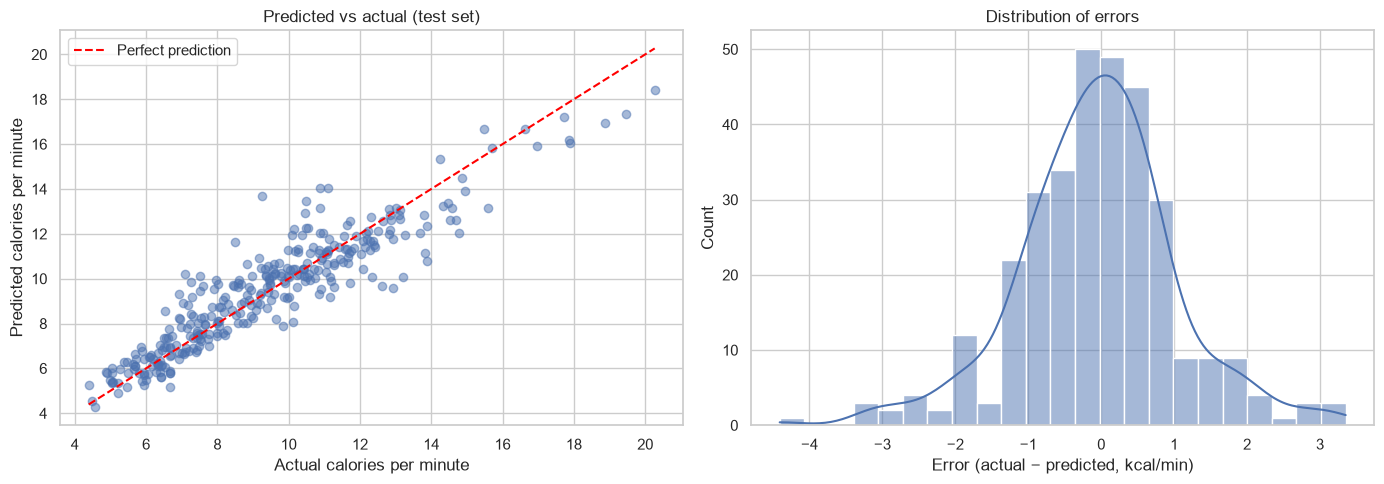

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5)
limits = [y_test.min(), y_test.max()]
axes[0].plot(limits, limits, color='red', linestyle='--', label='Perfect prediction')
axes[0].set_xlabel('Actual calories per minute')
axes[0].set_ylabel('Predicted calories per minute')
axes[0].set_title('Predicted vs actual (test set)')
axes[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_xlabel('Error (actual − predicted, kcal/min)')
axes[1].set_title('Distribution of errors')

plt.tight_layout()
plt.show()

### 3.2 Check: does it predict total calories well?

> The app will promise "you'll burn ~X kcal". To check that promise, we use cross-validated predictions of calories per minute, multiply by each person's actual session length, and compare with the calories they actually burned.

In [9]:
cv_rate_pred = cross_val_predict(calorie_rate_model, X_rate, y_rate, cv=kfold)
predicted_kcal = cv_rate_pred * df['Session_Duration_Minutes']
kcal_error = (predicted_kcal - df['Calories_Burned']).abs()

print(f"Mean absolute error in total calories: {kcal_error.mean():.1f} kcal")
print(f"Mean percentage error: {(kcal_error / df['Calories_Burned']).mean() * 100:.1f}%")

Mean absolute error in total calories: 32.3 kcal
Mean percentage error: 7.9%


### 3.3 What drives the prediction?

> The linear model's coefficients give an easy-to-explain picture (gradient boosting is more accurate but harder to read). Coefficients are in kcal/min; numeric features are per one standard deviation.

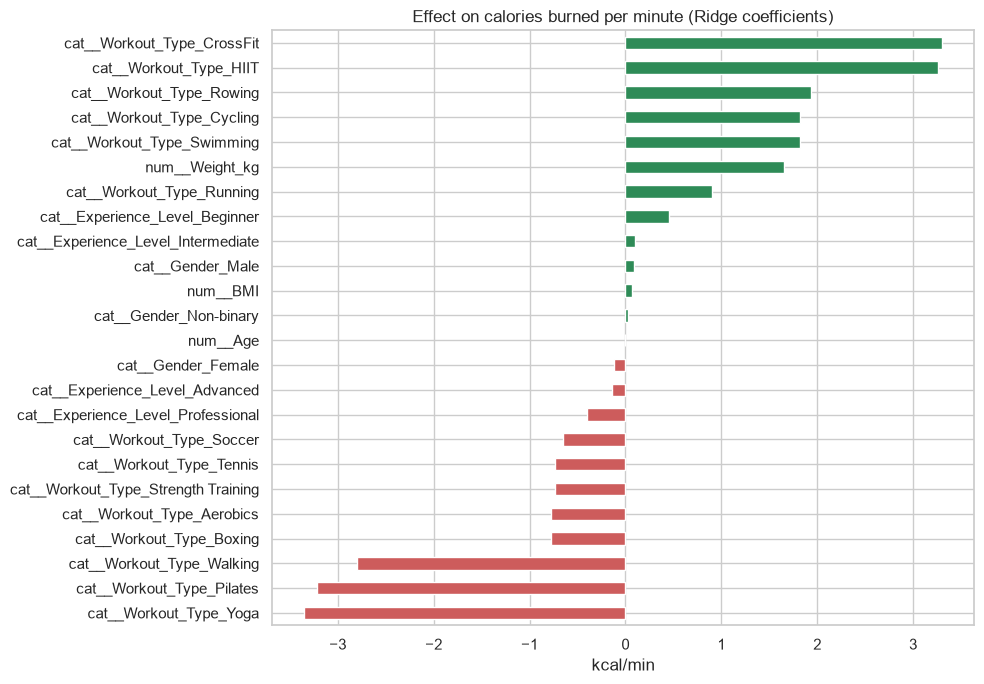

In [10]:
ridge_pipeline = Pipeline([('preprocessor', make_preprocessor(rate_numeric, rate_categorical)), ('model', Ridge())])
ridge_pipeline.fit(X_rate, y_rate)

coefficients = pd.Series(
    ridge_pipeline.named_steps['model'].coef_,
    index=ridge_pipeline.named_steps['preprocessor'].get_feature_names_out(),
).sort_values()

plt.figure(figsize=(10, 7))
coefficients.plot(kind='barh', color=np.where(coefficients > 0, 'seagreen', 'indianred'))
plt.title('Effect on calories burned per minute (Ridge coefficients)')
plt.xlabel('kcal/min')
plt.tight_layout()
plt.show()

> - **Workout type** has the largest effect: HIIT/CrossFit add ~3.3 kcal/min, Yoga/Pilates subtract ~3.3 kcal/min.
> - **Weight** is the strongest body feature: heavier people burn more energy for the same activity.
> - Beginners burn slightly more per minute than advanced users — consistent with the EDA (beginners train shorter but harder relative to their fitness).

## 4. The recommendation function

For a user and a calorie target:

1. Predict calories per minute for **all 14 workout types**.
2. Compute **minutes needed** = target ÷ predicted rate.
3. Compare to the **typical session length for the user's experience level** (median from the data, e.g. ~37 min for beginners, ~58 min for advanced users).
4. If a plan needs more than the longest session in the data (~70 min), **split it into equal sessions**.
5. Rank plans that fit in **one session** first, by how close they are to the user's typical session; split plans come after, least total time first.

**Target limit:** no session in the data burned more than ~806 kcal, so targets are limited to **800 kcal**. Without this limit, every large target returned the same three fastest-burning workouts with unrealistic durations (e.g. CrossFit for 126 min).

**Safety rule (domain knowledge, not learned from data):** beginners are not recommended the two highest-intensity workouts (HIIT, CrossFit — average intensity > 80% of max heart rate). The data cannot tell us this — beginners in the dataset do every workout type — so it is stated openly as a rule.

In [11]:
workout_intensity = df.groupby('Workout_Type')['Workout_Intensity'].mean().round(3)
typical_minutes = df.groupby('Experience_Level')['Session_Duration_Minutes'].median().round(1)

HIGH_INTENSITY_THRESHOLD = 0.80

def intensity_label(value):
    if value >= HIGH_INTENSITY_THRESHOLD:
        return 'High'
    elif value >= 0.70:
        return 'Moderate'
    return 'Low'

workout_profiles = {
    'intensity': workout_intensity.to_dict(),
    'typical_minutes': typical_minutes.to_dict(),
    'high_intensity_threshold': HIGH_INTENSITY_THRESHOLD,
    'max_minutes_observed': round(df['Session_Duration_Minutes'].max(), 1),
}

print('Average intensity by workout type:')
print(workout_intensity.sort_values())
print()
print('Typical session length (minutes) by experience level:')
print(typical_minutes)
print()
print('Longest session in the data (minutes):', workout_profiles['max_minutes_observed'])

Average intensity by workout type:
Workout_Type
Pilates              0.620
Walking              0.620
Yoga                 0.627
Aerobics             0.715
Boxing               0.716
Soccer               0.721
Tennis               0.721
Strength Training    0.722
Running              0.762
Cycling              0.769
Rowing               0.769
Swimming             0.774
HIIT                 0.817
CrossFit             0.820
Name: Workout_Intensity, dtype: float64

Typical session length (minutes) by experience level:
Experience_Level
Advanced        58.2
Beginner        36.6
Intermediate    45.0
Professional    60.6
Name: Session_Duration_Minutes, dtype: float64

Longest session in the data (minutes): 70.2


In [12]:
def recommend_workouts(age, gender, weight, height_cm, experience_level, target_calories, top_n=3):
    bmi = weight / (height_cm / 100) ** 2
    workout_types = sorted(workout_intensity.index)

    candidates = pd.DataFrame({
        'Age': age,
        'Gender': gender,
        'Weight_kg': weight,
        'BMI': bmi,
        'Experience_Level': experience_level,
        'Workout_Type': workout_types,
    })
    candidates['calories_per_min'] = calorie_rate_model.predict(candidates[rate_numeric + rate_categorical])
    candidates['minutes'] = target_calories / candidates['calories_per_min']
    candidates['intensity'] = candidates['Workout_Type'].map(workout_intensity)

    if experience_level == 'Beginner':
        candidates = candidates[candidates['intensity'] < HIGH_INTENSITY_THRESHOLD]

    # Split anything longer than the longest session in the data into equal sessions
    max_session = workout_profiles['max_minutes_observed']
    candidates['sessions'] = np.ceil(candidates['minutes'].round() / max_session).clip(lower=1).astype(int)
    candidates['minutes_per_session'] = (candidates['minutes'] / candidates['sessions']).round().astype(int)

    # Single sessions first (closest to the usual length), then split plans (least total time)
    usual_minutes = typical_minutes[experience_level]
    candidates['rank_score'] = np.where(
        candidates['sessions'] == 1,
        (candidates['minutes'] - usual_minutes).abs(),
        candidates['minutes'],
    )
    best = candidates.sort_values(['sessions', 'rank_score']).head(top_n)

    return [
        {
            'workout': row.Workout_Type,
            'sessions': int(row.sessions),
            'minutes_per_session': int(row.minutes_per_session),
            'calories_per_minute': round(row.calories_per_min, 1),
            'expected_calorie_burn': int(round(row.calories_per_min * row.sessions * row.minutes_per_session)),
            'intensity': intensity_label(row.intensity),
        }
        for row in best.itertuples()
    ]

### 4.1 Example recommendations

In [13]:
examples = [
    dict(age=22, gender='Male', weight=67, height_cm=180, experience_level='Beginner', target_calories=250),
    dict(age=35, gender='Female', weight=72, height_cm=162, experience_level='Intermediate', target_calories=400),
    dict(age=28, gender='Male', weight=85, height_cm=178, experience_level='Advanced', target_calories=700),
]

for user in examples:
    print(user)
    print(pd.DataFrame(recommend_workouts(**user)).to_string(index=False))
    print()

{'age': 22, 'gender': 'Male', 'weight': 67, 'height_cm': 180, 'experience_level': 'Beginner', 'target_calories': 250}
 workout  sessions  minutes_per_session  calories_per_minute  expected_calorie_burn intensity
 Walking         1                   39                  6.4                    251       Low
Aerobics         1                   32                  7.9                    252  Moderate
  Boxing         1                   32                  7.9                    252  Moderate

{'age': 35, 'gender': 'Female', 'weight': 72, 'height_cm': 162, 'experience_level': 'Intermediate', 'target_calories': 400}


          workout  sessions  minutes_per_session  calories_per_minute  expected_calorie_burn intensity
         Aerobics         1                   48                  8.3                    401  Moderate
           Soccer         1                   48                  8.3                    400  Moderate
Strength Training         1                   48                  8.3                    400  Moderate

{'age': 28, 'gender': 'Male', 'weight': 85, 'height_cm': 178, 'experience_level': 'Advanced', 'target_calories': 700}
 workout  sessions  minutes_per_session  calories_per_minute  expected_calorie_burn intensity
 Running         1                   62                 11.3                    698  Moderate
  Rowing         1                   53                 13.1                    697  Moderate
Swimming         1                   53                 13.3                    703  Moderate



> Same user, different targets: a small target leads to gentle workouts; a large target leads to high-burn workouts that fit into the usual session length; at 800 kcal some plans need two sessions.

In [14]:
for target in [200, 400, 600, 800]:
    print(f'Target {target} kcal (Intermediate, 30 y, Female, 65 kg, 165 cm):')
    print(pd.DataFrame(recommend_workouts(30, 'Female', 65, 165, 'Intermediate', target)).to_string(index=False))
    print()

Target 200 kcal (Intermediate, 30 y, Female, 65 kg, 165 cm):
workout  sessions  minutes_per_session  calories_per_minute  expected_calorie_burn intensity
   Yoga         1                   39                  5.1                    200       Low
Pilates         1                   38                  5.3                    200       Low
Walking         1                   34                  5.9                    201       Low

Target 400 kcal (Intermediate, 30 y, Female, 65 kg, 165 cm):
 workout  sessions  minutes_per_session  calories_per_minute  expected_calorie_burn intensity
 Running         1                   45                  8.9                    402  Moderate
  Rowing         1                   43                  9.4                    404  Moderate
Swimming         1                   40                  9.9                    397  Moderate

Target 600 kcal (Intermediate, 30 y, Female, 65 kg, 165 cm):
 workout  sessions  minutes_per_session  calories_per_minute  expec

## 5. Save the model for the API

> The fitted pipeline (preprocessing + model) is saved with `joblib`, exactly like the original models, plus a small JSON file with the workout intensity and typical session lengths used by the recommendation rules.

In [15]:
joblib.dump(calorie_rate_model, 'fitinsight_calorie_rate_model.joblib')

with open('workout_profiles.json', 'w') as f:
    json.dump(workout_profiles, f, indent=2)

print('Saved fitinsight_calorie_rate_model.joblib and workout_profiles.json')

Saved fitinsight_calorie_rate_model.joblib and workout_profiles.json


## 6. Summary

| | Original approach | Improved approach |
|---|---|---|
| Question asked | Which workout did this person choose? | How fast will this person burn calories in each workout? |
| Main model | Random Forest classifier (14 classes) | Gradient boosting regressor on calories/min |
| Quality | ~16–18% accuracy (baseline ~14.5%) | R² ≈ 0.86 (test), error ≈ 0.8 kcal/min; total calories within ~8% |
| Duration | Separate regressor (MAE ≈ 4.5 min) | Derived: target ÷ predicted rate |
| Expected calories | Echo of the user's input | Real prediction (rate × minutes) |
| Output | 1 workout | Top 3 workouts with duration, calories and intensity |
| Explainable? | Hard to justify | "HIIT reaches your target in 24 min, Yoga would need 50 min" |

**Limitations:**
- The dataset has only ~26 underweight users and ~15 professionals, so predictions for those groups are less reliable.
- Some workout types (e.g. Aerobics, Soccer, Strength Training) have almost identical burn rates, so they can appear together with the same numbers.
- Above ~600 kcal the same high-burn workouts (CrossFit, HIIT, Swimming) tend to win — this is expected, since they are the only ones that reach large targets in a normal session length.
- The beginner safety rule comes from domain knowledge, not the data.
- The recommender itself can only be properly evaluated with real user feedback (did users follow it and reach their target?).